# Hospital Stay Duration Prediction — Post-Treatment Support for Doctors

**Predictive Care · Group 24 · CS3501 Data Science and Engineering Project**

---

## The question this answers

A doctor who has already treated a road-accident patient wants a working estimate of how much
longer bed capacity will be needed.

> **Will this patient's stay be short (0-1 days), moderate (2-3 days), or extended (4+ days)?**

Like the discharge outcome model, this runs **after treatment** — length of stay so far,
transfer history, investigations and management given are all legitimate inputs, because the
doctor already knows them.

---

## Design commitments — same standards as the other two models

| Commitment | How it is enforced |
|---|---|
| Only post-treatment-appropriate information | Every candidate column audited in Section 3 |
| Honest performance estimate | Three-way split; holdout opened once (Section 15) |
| Decisions derived, not assumed | Feature set, class weights, and confidence layer all measured on validation |
| No sensitive attributes | Sex and ethnicity excluded from all features |
| Explanations grounded in the model | Permutation importance on holdout, not SHAP |

`4+ days` is the class that matters clinically — under-predicting it means a bed is freed up too
early in planning terms — and it's also the rarest (~7.7%). Same imbalance shape as discharge
outcome, same protective design around it.

**One field is deliberately excluded despite being statistically informative: `Discharge
Outcome`.** It is finalised at the same moment `total_days` becomes fixed — the two are decided
together, not one before the other — so it is not information a doctor has "in advance" while a
patient is still admitted. Section 3 explains this in full.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight

# Tree-native classifiers - not part of scikit-learn:
#   pip install catboost xgboost lightgbm
from catboost import CatBoostClassifier
import xgboost as xgb
import lightgbm as lgb

import joblib

RANDOM_STATE = 42
DATA_PATH = "Preprocessed_Dataset.csv"
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SEARCH_CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.random.seed(RANDOM_STATE)
print("Setup complete.")

Setup complete.


## 2. Load and normalise

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded {df_raw.shape[0]:,} patient records x {df_raw.shape[1]} columns")

df = df_raw.copy()
for c in df.columns:
    if df[c].dtype == object or str(df[c].dtype) == "str":
        df[c] = (df[c].astype(str).str.strip().str.lower()
                 .replace({"nan": np.nan, "none": np.nan, "": np.nan}))
df = df.rename(columns={"Collision With ": "Collision With"})
print("Text columns normalised.")

Loaded 6,178 patient records x 130 columns
Text columns normalised.


## 3. Eligibility audit — the post-treatment contract

Same rule as discharge outcome: anything the doctor already knows by the point of asking is fair
game, since this runs after treatment.

Three exclusions beyond the usual admin/ethical/bookkeeping ones:

| Class | Meaning |
|---|---|
| `TARGET_INPUT` | The three ward-day columns `total_days` (and the bucketed target) are built from — never features, they define the answer |
| `TARGET_ADJACENT` | `Discharge Outcome` and `Number of Wards Stayed` — decided at the same moment as the target, or near-redundant with it |
| `ADMIN` | Hospital/record identity, dates |
| `EXCLUDED_ETHICAL` | Sensitive attributes and socioeconomic fields |
| `BOOKKEEPING` | Auto-generated `_missing_reason` columns |
| `POST_ARRIVAL_ELIGIBLE` | Everything else |

**Why `Number of Wards Stayed` is excluded on redundancy, not timing:** it correlates 0.60 with
`total_days` — largely the same signal under a different unit. Keeping it would let the model
double-count length of stay rather than learning from genuinely separate facts.

**Why `Discharge Outcome` is excluded despite being statistically informative:** the association
is real but weak (complete recovery patients skew toward shorter stays, 64.2% vs 52.5% for
further-interventions patients at 0-1 days) — not the tautological relationship checked for and
ruled out with `Transfer To Next Hospital` in the discharge outcome model. The reason for
exclusion here is **timing, not correlation strength**: discharge outcome is finalised at the
same moment the stay ends, so it is never available to a doctor asking this question while the
patient is still admitted. An eligible-by-correlation field can still be ineligible by knowledge
timing — the same principle that excludes `TARGET_INPUT` fields in the severity model, applied to
a field that would otherwise pass a pure statistical screen.

An assertion enforces every column is classified.

In [3]:
TARGET_INPUT = ["Number of days in first ward", "Number of days in Second ward",
               "Number of days in Third ward"]

TARGET_ADJACENT = ["Discharge Outcome", "Number of Wards Stayed"]

ADMIN = ["Current Hospital Name", "First Hospital Name", "Incident At Time and Date",
         "Date Of Birth"]

EXCLUDED_ETHICAL = [
    "Bystander Expenditure per day", "Traveling Expenditure per day",
    "Total Traveling Expenditure For Whole Hospital Stay",
    "Family Monthly Income Before Accident", "Family Monthly Income After Accident",
    "Family Current Status", "Hospital Distance From Home", "Any Insurance Claim Type",
    "Any Other Hospital Admission Expenditure", "Vehicle Insured", "Vehicle Insurance Type",
    "Occupation", "Employment Type Name", "Educational Qualification", "Life Style",
    "Dress Name",
]

BOOKKEEPING = [c for c in df.columns if c.endswith("_missing_reason")]

_assigned = (set(TARGET_INPUT) | set(TARGET_ADJACENT) | set(ADMIN) | set(EXCLUDED_ETHICAL) |
             set(BOOKKEEPING))
POST_ARRIVAL_ELIGIBLE = [c for c in df.columns if c not in _assigned]

audit = pd.Series(
    {**{c: "TARGET_INPUT" for c in TARGET_INPUT},
     **{c: "TARGET_ADJACENT" for c in TARGET_ADJACENT},
     **{c: "ADMIN" for c in ADMIN},
     **{c: "EXCLUDED_ETHICAL" for c in EXCLUDED_ETHICAL},
     **{c: "BOOKKEEPING" for c in BOOKKEEPING},
     **{c: "POST_ARRIVAL_ELIGIBLE" for c in POST_ARRIVAL_ELIGIBLE}}
).reindex(df.columns)

assert audit.notna().all(), f"Unclassified: {list(audit[audit.isna()].index)}"
print(audit.value_counts().to_string())
print(f"\nAll {len(audit)} columns classified.")

BOOKKEEPING              65
POST_ARRIVAL_ELIGIBLE    40
EXCLUDED_ETHICAL         16
ADMIN                     4
TARGET_INPUT              3
TARGET_ADJACENT           2

All 130 columns classified.


## 4. Target: bucket total_days into stay-duration groups

The three ward-day columns collapse into `total_days`, same reasoning as the other two models —
`early_discharge` blanks become 0, not unknown.

**Buckets: 3, not 4.** An initial attempt split into four groups, but 0-day and 1-day stays were
the hardest to separate with the available signal and mean the same thing practically (both are
"discharged almost immediately"). Merging them into `0-1 days` is a simplification decided before
looking at model performance, not a response to weak results after the fact.

In [4]:
ward_cols = TARGET_INPUT

for c in ward_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    early = df[f"{c}_missing_reason"] == "early_discharge"
    df.loc[early, c] = df.loc[early, c].fillna(0)

df["total_days"] = df[ward_cols].sum(axis=1, min_count=1)
print(f"Missing total_days: {df['total_days'].isna().mean():.1%}")


def bucket_stay(days):
    if pd.isna(days):
        return np.nan
    if days <= 1:
        return "0-1 days"
    if days <= 3:
        return "2-3 days"
    return "4+ days"


TARGET_COL = "stay_duration_bucket"
df[TARGET_COL] = df["total_days"].map(bucket_stay)

df = df[df[TARGET_COL].notna()].copy()
print(f"\nTarget distribution:\n{df[TARGET_COL].value_counts()}")
print(f"\nTarget distribution (share):\n{df[TARGET_COL].value_counts(normalize=True).round(3)}")

Missing total_days: 0.0%

Target distribution:
stay_duration_bucket
0-1 days    4120
2-3 days    1582
4+ days      476
Name: count, dtype: int64

Target distribution (share):
stay_duration_bucket
0-1 days    0.667
2-3 days    0.256
4+ days     0.077
Name: proportion, dtype: float64


## 5. Candidate features

Post-treatment eligible fields, hand-picked for clinical relevance to a length-of-stay question —
the same set discharge outcome used, minus `Discharge Outcome` itself (excluded in Section 3).

In [5]:
CANDIDATE_FEATURES = [
    # demographics
    "Age",
    # accident circumstances
    "Mode of Transport to the Hospital", "Time Taken To Reach Hospital", "Vehicle Type",
    "Helmet Worn", "Collision With", "Approximate Speed", "Road Type", "Road Condition",
    "Visiblity", "Road Signals Exist", "Collision Force From", "Alcohol Consumption",
    "Illicit Drugs",
    # injury detail
    "Site of Injury No1", "Type of injury No 1", "Site of injury No 2", "Type of Injury No 2",
    # escalation of care
    "Transfer To Next Hospital", "Treatment During Tranfer", "State of Transfer",
    # treatment given
    "Investigation Done", "Management Name 1", "Management Name 2",
]

missing_from_data = [c for c in CANDIDATE_FEATURES if c not in df.columns]
assert not missing_from_data, f"Candidate features not in data: {missing_from_data}"
outside_eligible = [c for c in CANDIDATE_FEATURES if c not in POST_ARRIVAL_ELIGIBLE]
assert not outside_eligible, f"Candidate features outside the eligible set: {outside_eligible}"

print(f"{len(CANDIDATE_FEATURES)} candidate features, all confirmed eligible.")

24 candidate features, all confirmed eligible.


## 6. Three-way split

Same protocol throughout the project: **train (60%)** fits models, **validation (20%)** drives
every decision, **holdout (20%)** opens once, in Section 15.

Stratified — `4+ days` sits at ~7.7% prevalence, so an unstratified split risks a materially
different rare-class rate across the three sets.

In [6]:
X_all = df[CANDIDATE_FEATURES].copy()
y_all = df[TARGET_COL].copy()

X_dev, X_hold, y_dev, y_hold = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE)

for name, y_part in [("Train", y_train), ("Validation", y_val), ("Holdout", y_hold)]:
    print(f"{name:12s} {len(y_part):5,} rows")
    print(f"  {y_part.value_counts(normalize=True).round(3).to_dict()}")
print("\nHoldout is not read again until Section 15.")

Train        3,706 rows
  {'0-1 days': 0.667, '2-3 days': 0.256, '4+ days': 0.077}
Validation   1,236 rows
  {'0-1 days': 0.667, '2-3 days': 0.256, '4+ days': 0.077}
Holdout      1,236 rows
  {'0-1 days': 0.667, '2-3 days': 0.256, '4+ days': 0.077}

Holdout is not read again until Section 15.


## 7. Feature selection

**Screening (diagnostic).** Chi-squared + Cramér's V for categoricals, Kruskal-Wallis for
ordinal — same method used throughout this project.

**Decision by measured performance, not by the screening rule alone.** Screened vs all-candidates
feature sets are compared on validation; the winner is used regardless of which one the screening
test alone would have picked.

In [7]:
AGE_ORDER = ["1-9", "10-19", "20-29", "30-39", "40-49", "50-59",
             "60-69", "70-79", "80-89", "90-100"]
TIME_ORDER = ["less than 15 minutes", "15 minutes - 30 minutes", "30 minutes - 1 hour",
             "1 hour - 2 hour", "more than 2 hour"]

ORDINAL_FEATURES = ["Age", "Time Taken To Reach Hospital"]
NOMINAL_FEATURES = [c for c in CANDIDATE_FEATURES if c not in ORDINAL_FEATURES]

val_df = X_train.copy()
val_df["target"] = y_train.values

screen_rows = []
for col, order in [("Age", AGE_ORDER), ("Time Taken To Reach Hospital", TIME_ORDER)]:
    mapping = {v: i for i, v in enumerate(order)}
    groups = [g[col].map(mapping).dropna() for _, g in val_df.groupby("target")]
    h, p = stats.kruskal(*[g for g in groups if len(g) > 0])
    screen_rows.append({"feature": col, "test": "kruskal", "p_value": p, "effect_size": np.nan})

for col in NOMINAL_FEATURES:
    ct = pd.crosstab(val_df[col], val_df["target"])
    if ct.shape[0] < 2:
        continue
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    screen_rows.append({"feature": col, "test": "chi2", "p_value": p, "effect_size": v})

screening = pd.DataFrame(screen_rows)
screening["keep"] = screening.apply(
    lambda r: (r["p_value"] <= 0.05) if pd.isna(r["effect_size"])
    else (r["p_value"] <= 0.05 and r["effect_size"] >= 0.05), axis=1)
print(screening.sort_values("p_value").to_string(index=False, formatters={
    "p_value": "{:.3g}".format, "effect_size": lambda x: "n/a" if pd.isna(x) else f"{x:.3f}"}))

                          feature    test  p_value effect_size  keep
                Management Name 2    chi2 4.93e-93       0.261  True
                Management Name 1    chi2 1.11e-52       0.216  True
               Investigation Done    chi2 4.76e-31       0.162  True
              Type of injury No 1    chi2 6.63e-30       0.184  True
              Site of injury No 2    chi2 9.15e-12       0.166  True
               Site of Injury No1    chi2 2.12e-11       0.169  True
              Type of Injury No 2    chi2  0.00253       0.146  True
        Transfer To Next Hospital    chi2  0.00292       0.056  True
             Collision Force From    chi2   0.0947       0.054 False
     Time Taken To Reach Hospital kruskal    0.102         NaN False
                Approximate Speed    chi2    0.183       0.040 False
               Road Signals Exist    chi2    0.241       0.034 False
                   Road Condition    chi2    0.244       0.031 False
                    Illicit Drugs 

In [8]:
CAT_COLS = NOMINAL_FEATURES
NUM_COLS = ORDINAL_FEATURES


def build_preprocessor(cols):
    cats = [c for c in cols if c in CAT_COLS]
    nums = [c for c in cols if c not in cats]
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), nums),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                   min_frequency=20))]), cats),
    ])


def encode_ordinal(frame, cols):
    out = frame.copy()
    for col, order in [("Age", AGE_ORDER), ("Time Taken To Reach Hospital", TIME_ORDER)]:
        if col in cols and col in out.columns:
            out[col] = out[col].map({v: i for i, v in enumerate(order)})
    return out


PRIMARY_CLASS = "4+ days"


def recall_primary_class(y_true, y_pred):
    labels = sorted(set(y_true) | set(y_pred))
    recalls = recall_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    by_label = dict(zip(labels, recalls))
    return by_label.get(PRIMARY_CLASS, 0.0)


REFERENCE_MODEL = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5, class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=-1)

strict = [c for c in CANDIDATE_FEATURES if c in set(screening.loc[screening["keep"], "feature"])]
everything = list(CANDIDATE_FEATURES)

selection = []
for name, cols in [("strict (p and effect size)", strict), ("all candidates", everything)]:
    tr = encode_ordinal(X_train, cols)[cols]
    va = encode_ordinal(X_val, cols)[cols]
    pipe = Pipeline([("pre", build_preprocessor(cols)), ("clf", REFERENCE_MODEL)])
    pipe.fit(tr, y_train)
    pred = pipe.predict(va)
    selection.append({"feature set": name, "n_features": len(cols),
                      "val_recall_4plus_days": recall_primary_class(y_val, pred),
                      "val_f1_macro": f1_score(y_val, pred, average="macro")})

selection = pd.DataFrame(selection).sort_values(
    "val_recall_4plus_days", ascending=False).reset_index(drop=True)
print(selection.to_string(index=False, float_format="%.4f"))

winner = selection.loc[0, "feature set"]
FEATURES = {"strict (p and effect size)": strict, "all candidates": everything}[winner]
DROPPED = [c for c in CANDIDATE_FEATURES if c not in FEATURES]
CAT_FEATURES = [c for c in FEATURES if c in CAT_COLS]
NUM_FEATURES = [c for c in FEATURES if c in NUM_COLS]

print(f"\nSelected '{winner}' -> {len(FEATURES)} features, {len(DROPPED)} dropped")
print(f"Dropped: {DROPPED}")

               feature set  n_features  val_recall_4plus_days  val_f1_macro
strict (p and effect size)           8                 0.4316        0.4945
            all candidates          24                 0.2632        0.5047

Selected 'strict (p and effect size)' -> 8 features, 16 dropped
Dropped: ['Age', 'Mode of Transport to the Hospital', 'Time Taken To Reach Hospital', 'Vehicle Type', 'Helmet Worn', 'Collision With', 'Approximate Speed', 'Road Type', 'Road Condition', 'Visiblity', 'Road Signals Exist', 'Collision Force From', 'Alcohol Consumption', 'Illicit Drugs', 'Treatment During Tranfer', 'State of Transfer']


## 8. Rare-category consolidation

Categories with fewer than 20 training rows are merged into `"other"` — fit on train only,
applied identically to validation and holdout.

In [9]:
RARE_MIN_COUNT = 20

rare_maps = {}
for col in CAT_FEATURES:
    counts = X_train[col].value_counts(dropna=True)
    keep = set(counts[counts >= RARE_MIN_COUNT].index)
    if len(keep) < counts.shape[0]:
        rare_maps[col] = keep


def consolidate(series, keep_set):
    return series.where(series.isna() | series.isin(keep_set), "other")


for col, keep_set in rare_maps.items():
    n_dropped = X_train[col].value_counts()[lambda s: ~s.index.isin(keep_set)].shape[0]
    print(f"{col}: {n_dropped} rare categories merged into 'other'")
    X_train[col] = consolidate(X_train[col], keep_set)
    X_val[col] = consolidate(X_val[col], keep_set)
    X_hold[col] = consolidate(X_hold[col], keep_set)

X_train, X_val, X_hold = X_train[FEATURES], X_val[FEATURES], X_hold[FEATURES]
X_train_enc = encode_ordinal(X_train, FEATURES)
X_val_enc = encode_ordinal(X_val, FEATURES)
X_hold_enc = encode_ordinal(X_hold, FEATURES)

print(f"\nFinal features ({len(FEATURES)}): {FEATURES}")

Site of Injury No1: 13 rare categories merged into 'other'
Type of injury No 1: 8 rare categories merged into 'other'
Site of injury No 2: 28 rare categories merged into 'other'
Type of Injury No 2: 5 rare categories merged into 'other'
Investigation Done: 2 rare categories merged into 'other'
Management Name 1: 7 rare categories merged into 'other'
Management Name 2: 5 rare categories merged into 'other'

Final features (8): ['Site of Injury No1', 'Type of injury No 1', 'Site of injury No 2', 'Type of Injury No 2', 'Transfer To Next Hospital', 'Investigation Done', 'Management Name 1', 'Management Name 2']


## 9. Model comparison

Six candidates plus a stratified dummy: **CatBoost**, **XGBoost**, **LightGBM**,
**HistGradientBoosting**, **Logistic Regression**, **Random Forest**.

**One dispatch layer** hides how each library wants its data. CatBoost's own categorical handling
rejects a float `NaN` sitting inside a pandas `category` dtype column — it needs missing values as
the explicit string `"missing"`. HistGradientBoosting, LightGBM, and XGBoost (with
`enable_categorical=True`) all accept `NaN` inside `category` dtype natively. Getting this branch
wrong crashes CatBoost outright rather than silently misbehaving, so it is handled explicitly
per-library rather than with one shared rule.

**Metric.** Recall on `4+ days` is primary — under-predicting it means bed-planning assumes a
shorter stay than actually happens. Macro-F1 reported alongside.

In [10]:
def prepare_X(name, X):
    """Return X in the encoding a given model family expects.

    CatBoost's own categorical handling rejects a float NaN sitting inside a pandas
    `category` dtype column - it wants an explicit string, so missing values are filled with
    the literal "missing" before casting to str. HistGradientBoosting, LightGBM, and XGBoost
    (with enable_categorical=True) all accept NaN inside a `category` dtype column natively,
    so they get that instead.
    """
    out = X.copy()
    if name == "CatBoost":
        for c in CAT_FEATURES:
            out[c] = out[c].astype(object).where(out[c].notna(), "missing").astype(str)
        return out
    if name in ("HistGradientBoosting", "LightGBM", "XGBoost"):
        for c in CAT_FEATURES:
            out[c] = out[c].astype("category")
        return out
    return out  # Logistic Regression / Random Forest go through the one-hot preprocessor


def fit_model(name, X, y, params=None, weights=None):
    """Fit any candidate model family through one call, class weights handled per-library."""
    params = params or {}
    Xp = prepare_X(name, X)

    if name == "CatBoost":
        classes = sorted(y.unique())
        kwargs = dict(random_state=RANDOM_STATE, verbose=0, loss_function="MultiClass")
        kwargs.update({"class_weights": [weights[c] for c in classes]} if weights is not None
                      else {"auto_class_weights": "Balanced"})
        cat_idx_here = [Xp.columns.get_loc(c) for c in CAT_FEATURES]
        m = CatBoostClassifier(**kwargs, **params)
        m.fit(Xp, y, cat_features=cat_idx_here, verbose=0)
        return m

    if name == "HistGradientBoosting":
        cw = weights if weights is not None else "balanced"
        m = HistGradientBoostingClassifier(categorical_features="from_dtype", class_weight=cw,
                                           random_state=RANDOM_STATE, **params)
        m.fit(Xp, y)
        return m

    if name == "LightGBM":
        cw = weights if weights is not None else "balanced"
        m = lgb.LGBMClassifier(random_state=RANDOM_STATE, class_weight=cw, verbosity=-1, **params)
        m.fit(Xp, y)
        return m

    if name == "XGBoost":
        classes = sorted(y.unique())
        label_map = {c: i for i, c in enumerate(classes)}
        sample_weight = y.map(weights).values if weights is not None else None
        m = xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric="mlogloss",
                              objective="multi:softprob", enable_categorical=True,
                              tree_method="hist", **params)
        m.fit(Xp, y.map(label_map), sample_weight=sample_weight)
        m.label_map_, m.inv_label_map_ = label_map, {i: c for c, i in label_map.items()}
        return m

    if name in ("Logistic Regression", "Random Forest"):
        cw = weights if weights is not None else "balanced"
        clean_params = {k.replace("clf__", ""): v for k, v in params.items()}
        clf = (LogisticRegression(max_iter=3000, class_weight=cw, random_state=RANDOM_STATE,
                                  **clean_params) if name == "Logistic Regression" else
              RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, class_weight=cw,
                                     **clean_params))
        m = Pipeline([("pre", preprocessor), ("clf", clf)])
        m.fit(Xp, y)
        return m

    raise ValueError(f"Unknown model family: {name}")


def predict_model(name, model, X):
    Xp = prepare_X(name, X)
    pred = model.predict(Xp)
    if name == "CatBoost":
        return pred.flatten()
    if name == "XGBoost":
        return pd.Series(pred).map(model.inv_label_map_).values
    return pred


def predict_proba_model(name, model, X):
    Xp = prepare_X(name, X)
    proba = model.predict_proba(Xp)
    if name == "XGBoost":
        classes = [model.inv_label_map_[i] for i in range(len(model.inv_label_map_))]
    else:
        classes = list(getattr(model, "classes_", sorted(y_train.unique())))
    return proba, classes


preprocessor = build_preprocessor(FEATURES)

CANDIDATE_MODEL_NAMES = ["Dummy (stratified)", "Logistic Regression", "Random Forest",
                         "HistGradientBoosting", "CatBoost", "XGBoost", "LightGBM"]

comparison = []
for name in CANDIDATE_MODEL_NAMES:
    if name == "Dummy (stratified)":
        m = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)
        m.fit(X_train_enc, y_train)
        pred = m.predict(X_val_enc)
    else:
        m = fit_model(name, X_train_enc, y_train)
        pred = predict_model(name, m, X_val_enc)
    comparison.append({"model": name,
                       "recall_4plus_days": recall_primary_class(y_val, pred),
                       "recall_0_1_days": recall_score(
                           y_val, pred, labels=["0-1 days"], average=None, zero_division=0)[0],
                       "f1_macro": f1_score(y_val, pred, average="macro"),
                       "precision_macro": precision_score(y_val, pred, average="macro",
                                                          zero_division=0)})

results = pd.DataFrame(comparison).sort_values(
    "recall_4plus_days", ascending=False).reset_index(drop=True)
print(results.to_string(index=False, float_format="%.4f"))
BEST_MODEL = results.loc[0, "model"]
if BEST_MODEL.startswith("Dummy"):
    BEST_MODEL = results.loc[1, "model"]
print(f"\nSelected for tuning: {BEST_MODEL}")

               model  recall_4plus_days  recall_0_1_days  f1_macro  precision_macro
 Logistic Regression             0.4842           0.6687    0.4612           0.4592
            LightGBM             0.3684           0.7172    0.4697           0.4627
HistGradientBoosting             0.3474           0.7233    0.4743           0.4673
       Random Forest             0.2526           0.7985    0.4892           0.4899
            CatBoost             0.2211           0.7900    0.4903           0.4965
             XGBoost             0.1789           0.8823    0.4906           0.5767
  Dummy (stratified)             0.0947           0.6578    0.3209           0.3206

Selected for tuning: Logistic Regression


## 10. Hyperparameter tuning

Randomised search, scored on recall(4+ days) via cross-validation **inside training**, through
the same dispatch layer — whichever model won Section 9, its own search space is used.

In [11]:
from sklearn.metrics import make_scorer

fi_scorer = make_scorer(recall_primary_class)

PARAM_SPACES = {
    "CatBoost": {"depth": [4, 5, 6, 7, 8], "learning_rate": [0.03, 0.05, 0.08, 0.1],
                "l2_leaf_reg": [1, 3, 5, 8], "iterations": [200, 300, 400],
                "border_count": [32, 64, 128]},
    "HistGradientBoosting": {"learning_rate": [0.02, 0.05, 0.08, 0.1],
                             "max_leaf_nodes": [7, 15, 31, 63], "min_samples_leaf": [10, 20, 40],
                             "l2_regularization": [0.0, 0.1, 1.0], "max_iter": [150, 250, 350]},
    "XGBoost": {"max_depth": [3, 4, 5, 6, 8], "learning_rate": [0.03, 0.05, 0.08, 0.1],
               "n_estimators": [150, 250, 350], "min_child_weight": [1, 3, 5],
               "subsample": [0.7, 0.85, 1.0]},
    "LightGBM": {"num_leaves": [15, 31, 63], "learning_rate": [0.03, 0.05, 0.08, 0.1],
                "n_estimators": [150, 250, 350], "min_child_samples": [10, 20, 40],
                "reg_lambda": [0.0, 0.1, 1.0]},
    "Logistic Regression": {"C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    "Random Forest": {"n_estimators": [200, 300, 400], "max_depth": [None, 8, 12, 16],
                      "min_samples_leaf": [2, 5, 10, 20]},
}

N_ITER = 20
rng = np.random.RandomState(RANDOM_STATE)
space = PARAM_SPACES[BEST_MODEL]
sampled = set()
while len(sampled) < min(N_ITER, int(np.prod([len(v) for v in space.values()]))):
    combo = tuple(rng.choice(space[k]) for k in space)
    sampled.add(combo)

best_score, best_params, tuning_log = -1, None, []
for combo in sampled:
    params = dict(zip(space.keys(), [v.item() if hasattr(v, "item") else v for v in combo]))
    recs = []
    for tr_idx, va_idx in SEARCH_CV.split(X_train_enc, y_train):
        Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[va_idx]
        yt, yv = y_train.iloc[tr_idx], y_train.iloc[va_idx]
        m = fit_model(BEST_MODEL, Xt, yt, params=params)
        recs.append(recall_primary_class(yv, predict_model(BEST_MODEL, m, Xv)))
    score = np.mean(recs)
    tuning_log.append({**params, "cv_recall_4plus": score})
    if score > best_score:
        best_score, best_params = score, params

print(f"{BEST_MODEL} search: {len(sampled)} random combinations tried "
      f"(of {np.prod([len(v) for v in space.values()])} possible)")
print(f"Best CV recall(4+ days): {best_score:.4f}")
print(f"Best params: {best_params}")

tuned_model = fit_model(BEST_MODEL, X_train_enc, y_train, params=best_params)
val_pred_tuned = predict_model(BEST_MODEL, tuned_model, X_val_enc)
print(f"\nTuned model on validation: recall(4+ days) = "
      f"{recall_primary_class(y_val, val_pred_tuned):.4f}")

Logistic Regression search: 7 random combinations tried (of 7 possible)
Best CV recall(4+ days): 0.5525
Best params: {'C': 0.1}

Tuned model on validation: recall(4+ days) = 0.5053


## 11. Class-weight balance — chosen jointly with the model

Base class weighting protects the rare class somewhat; a stated clinical assumption sharpens it:

> Under-predicting `4+ days` costs more than over-predicting it, since bed planning that assumes
> too short a stay causes real capacity problems.

Multipliers are swept on validation, guarded by a floor: the other two classes must not drop
below `OTHER_CLASS_RECALL_FLOOR`, so the model doesn't buy `4+ days` recall by ignoring the
majority classes.

 multiplier  recall_4plus_days  recall_0_1_days  recall_2_3_days
     1.0000             0.5053           0.6784           0.3628
     1.5000             0.7263           0.6323           0.1893
     2.0000             0.8105           0.5837           0.1136
     3.0000             0.9263           0.4587           0.0568
     5.0000             0.9684           0.3811           0.0221

Selected multiplier: 1.0
  recall(4+)=0.505  recall(0-1)=0.678  recall(2-3)=0.363


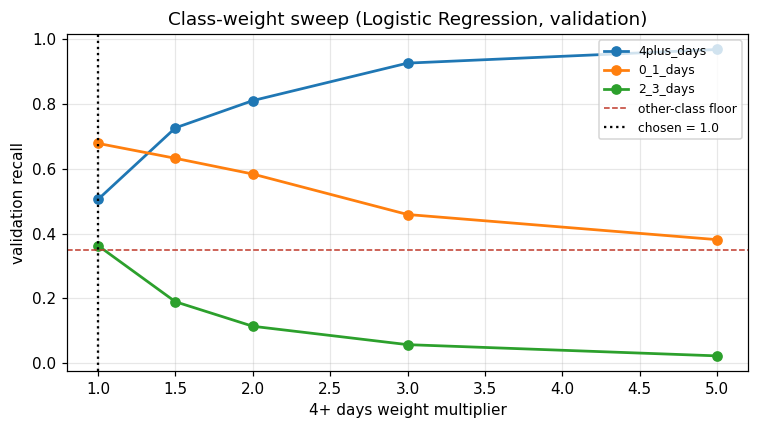

In [12]:
OTHER_CLASS_RECALL_FLOOR = 0.35
WEIGHT_MULTIPLIERS = [1, 1.5, 2, 3, 5]


def class_weights_for_multiplier(y, multiplier, boost_class=PRIMARY_CLASS):
    classes = sorted(y.unique())
    base = compute_class_weight("balanced", classes=np.array(classes), y=y)
    weights = dict(zip(classes, base))
    weights[boost_class] = weights[boost_class] * multiplier
    return weights


sweep_rows = []
for mult in WEIGHT_MULTIPLIERS:
    weights = class_weights_for_multiplier(y_train, mult)
    m = fit_model(BEST_MODEL, X_train_enc, y_train, params=best_params, weights=weights)
    pred = predict_model(BEST_MODEL, m, X_val_enc)

    labels = sorted(set(y_val) | set(pred))
    recalls = dict(zip(labels, recall_score(y_val, pred, labels=labels, average=None,
                                            zero_division=0)))
    sweep_rows.append({"multiplier": mult,
                       "recall_4plus_days": recalls.get("4+ days", 0),
                       "recall_0_1_days": recalls.get("0-1 days", 0),
                       "recall_2_3_days": recalls.get("2-3 days", 0)})

sweep = pd.DataFrame(sweep_rows)
print(sweep.to_string(index=False, float_format="%.4f"))

valid = sweep[(sweep["recall_0_1_days"] >= OTHER_CLASS_RECALL_FLOOR) &
             (sweep["recall_2_3_days"] >= OTHER_CLASS_RECALL_FLOOR)]
if valid.empty:
    print(f"\nNo multiplier kept both other classes' recall >= {OTHER_CLASS_RECALL_FLOOR}.")
    winner = sweep.loc[sweep["recall_4plus_days"].idxmax()]
else:
    winner = valid.loc[valid["recall_4plus_days"].idxmax()]

WEIGHT_MULTIPLIER = winner["multiplier"]
print(f"\nSelected multiplier: {WEIGHT_MULTIPLIER}")
print(f"  recall(4+)={winner['recall_4plus_days']:.3f}  "
      f"recall(0-1)={winner['recall_0_1_days']:.3f}  recall(2-3)={winner['recall_2_3_days']:.3f}")

plt.figure(figsize=(7, 4))
for col in ["recall_4plus_days", "recall_0_1_days", "recall_2_3_days"]:
    plt.plot(sweep["multiplier"], sweep[col], "o-", lw=1.8, label=col.replace("recall_", ""))
plt.axhline(OTHER_CLASS_RECALL_FLOOR, color="#c0392b", ls="--", lw=1, label="other-class floor")
plt.axvline(WEIGHT_MULTIPLIER, color="k", ls=":", lw=1.5, label=f"chosen = {WEIGHT_MULTIPLIER}")
plt.xlabel("4+ days weight multiplier"); plt.ylabel("validation recall")
plt.title(f"Class-weight sweep ({BEST_MODEL}, validation)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(ARTIFACTS / "weight_sweep.png", bbox_inches="tight"); plt.show()

final_weights = class_weights_for_multiplier(y_train, WEIGHT_MULTIPLIER)
final_model = fit_model(BEST_MODEL, X_train_enc, y_train, params=best_params,
                        weights=final_weights)

## 12. Held-out evaluation — opened once

Feature set, model, hyperparameters, and class-weight balance were all chosen on train and
validation. The holdout is read here for the first and only time.

HELD-OUT RESULTS (first and only reading)
              precision    recall  f1-score   support

    0-1 days      0.815     0.669     0.735       824
    2-3 days      0.338     0.322     0.330       317
     4+ days      0.186     0.505     0.272        95

    accuracy                          0.567      1236
   macro avg      0.446     0.499     0.445      1236
weighted avg      0.644     0.567     0.595      1236

Per-class recall: {'0-1 days': np.float64(0.669), '2-3 days': np.float64(0.322), '4+ days': np.float64(0.505)}
F1 macro: 0.445


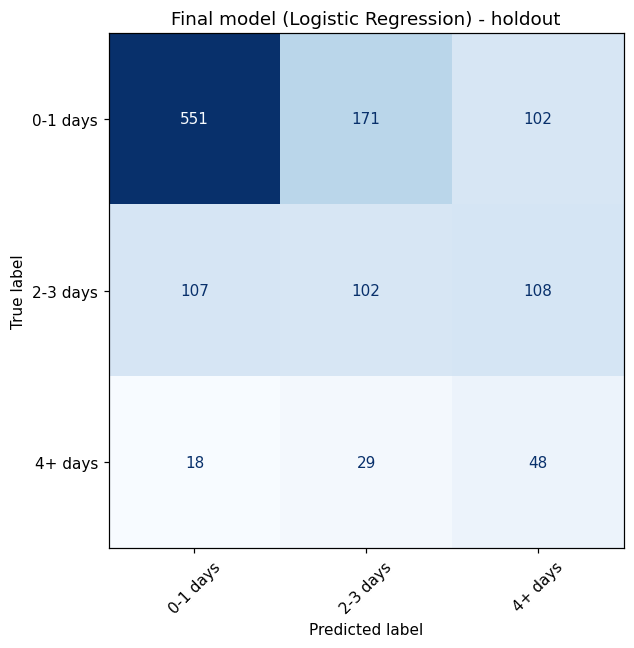

In [13]:
y_pred_hold = predict_model(BEST_MODEL, final_model, X_hold_enc)

print("=" * 58)
print("HELD-OUT RESULTS (first and only reading)")
print("=" * 58)
print(classification_report(y_hold, y_pred_hold, digits=3))

labels_order = ["0-1 days", "2-3 days", "4+ days"]
hold_recalls = dict(zip(labels_order, recall_score(y_hold, y_pred_hold, labels=labels_order,
                                                   average=None, zero_division=0)))
print("Per-class recall:", {k: round(v, 3) for k, v in hold_recalls.items()})
print(f"F1 macro: {f1_score(y_hold, y_pred_hold, average='macro'):.3f}")

cm = confusion_matrix(y_hold, y_pred_hold, labels=labels_order)
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(cm, display_labels=labels_order).plot(ax=ax, xticks_rotation=45,
                                                              colorbar=False, cmap="Blues")
plt.title(f"Final model ({BEST_MODEL}) - holdout"); ax.grid(False)
plt.tight_layout(); plt.savefig(ARTIFACTS / "holdout_confusion.png", bbox_inches="tight"); plt.show()

## 13. What the model pays attention to

Permutation importance on the holdout, not SHAP — consistent across all three models in this
project.

                  feature  importance    std
        Management Name 1      0.1347 0.0239
       Investigation Done      0.1126 0.0205
      Type of injury No 1      0.0916 0.0298
       Site of Injury No1      0.0558 0.0283
      Site of injury No 2      0.0253 0.0171
Transfer To Next Hospital     -0.0032 0.0170
        Management Name 2     -0.0053 0.0320
      Type of Injury No 2     -0.0074 0.0106


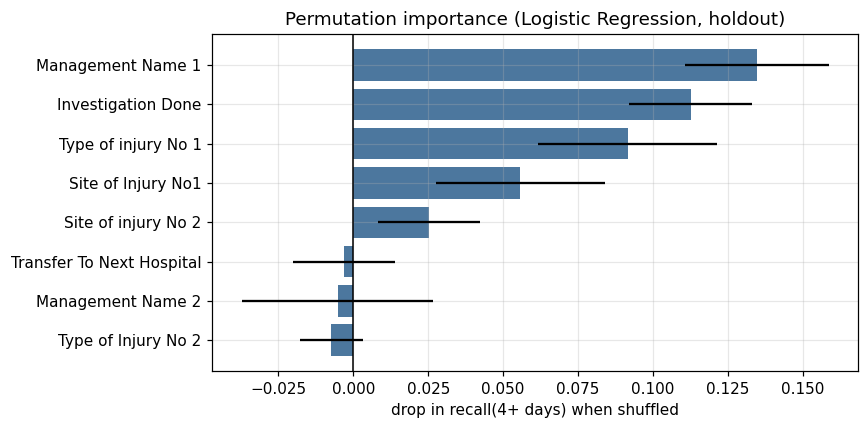

In [14]:
def score_fn(estimator, X, y):
    pred = predict_model(BEST_MODEL, estimator, X)
    return recall_primary_class(y, pred)


perm = permutation_importance(final_model, X_hold_enc, y_hold, scoring=score_fn,
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)

importance = (pd.DataFrame({"feature": X_hold_enc.columns, "importance": perm.importances_mean,
                            "std": perm.importances_std})
              .sort_values("importance", ascending=False).reset_index(drop=True))
print(importance.to_string(index=False, float_format="%.4f"))

plt.figure(figsize=(8, max(4, 0.34 * len(importance))))
top = importance.iloc[::-1]
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="#2c5f8d", alpha=0.85)
plt.axvline(0, color="k", lw=1)
plt.xlabel("drop in recall(4+ days) when shuffled")
plt.title(f"Permutation importance ({BEST_MODEL}, holdout)")
plt.tight_layout(); plt.savefig(ARTIFACTS / "permutation_importance.png", bbox_inches="tight")
plt.show()

## 14. Confidence layer — derived, not assumed

The completeness floor is measured: recall(4+ days) is checked per completeness level on
validation, and the floor sits at the lowest level where the model still performs usefully.

In [15]:
MIN_USABLE_RECALL = 0.25

completeness_val = X_val.notna().sum(axis=1) / len(FEATURES)
p_val_pred = predict_model(BEST_MODEL, final_model, X_val_enc)

floor_rows = []
for level in sorted(completeness_val.unique()):
    at_level = completeness_val == level
    if at_level.sum() < 20:
        continue
    floor_rows.append({"completeness": level, "patients": int(at_level.sum()),
                       "recall_4plus": recall_primary_class(y_val[at_level], p_val_pred[at_level])})

floors = pd.DataFrame(floor_rows).sort_values("completeness")
print(floors.to_string(index=False, float_format="%.3f"))

usable = floors.loc[floors["recall_4plus"] >= MIN_USABLE_RECALL, "completeness"]
COMPLETENESS_FLOOR = float(usable.min()) if not usable.empty else 0.0
print(f"\nCompleteness floor: {COMPLETENESS_FLOOR:.2f} "
      f"({int(np.ceil(COMPLETENESS_FLOOR * len(FEATURES)))} of {len(FEATURES)} fields)")

 completeness  patients  recall_4plus
        0.375        69         0.000
        0.500        37         0.000
        0.625        68         0.500
        0.750       122         0.000
        0.875       678         0.420
        1.000       262         0.619

Completeness floor: 0.62 (5 of 8 fields)


In [16]:
LOW_CONF_PROB = 0.50

DOCTOR_LABELS = {
    "Age": "age", "Mode of Transport to the Hospital": "how they reached hospital",
    "Time Taken To Reach Hospital": "time taken to reach hospital", "Vehicle Type": "vehicle type",
    "Helmet Worn": "helmet worn", "Collision With": "what they collided with",
    "Approximate Speed": "approximate speed", "Road Type": "road type",
    "Road Condition": "road condition", "Visiblity": "visibility",
    "Road Signals Exist": "road signals present", "Collision Force From": "collision direction",
    "Alcohol Consumption": "alcohol consumption", "Illicit Drugs": "illicit drug use",
    "Site of Injury No1": "main injury site", "Type of injury No 1": "main injury type",
    "Site of injury No 2": "second injury site", "Type of Injury No 2": "second injury type",
    "Transfer To Next Hospital": "transferred to another hospital",
    "Treatment During Tranfer": "treatment during transfer", "State of Transfer": "transfer state",
    "Investigation Done": "investigation done", "Management Name 1": "primary management given",
    "Management Name 2": "secondary management given",
}


def predict_stay_duration(record: dict) -> dict:
    present = sum(1 for f in FEATURES if record.get(f) is not None and not pd.isna(record.get(f)))
    completeness = present / len(FEATURES)

    if completeness < COMPLETENESS_FLOOR:
        return {"prediction": None, "probability": None, "completeness": round(completeness, 3),
                "status": f"REFUSED - only {present} of {len(FEATURES)} fields recorded"}

    row = pd.DataFrame([{f: record.get(f) for f in FEATURES}])
    row = encode_ordinal(row, FEATURES)

    proba, classes = predict_proba_model(BEST_MODEL, final_model, row)
    proba = proba[0]
    pred_idx = int(np.argmax(proba))
    pred_label, pred_prob = classes[pred_idx], float(proba[pred_idx])

    status = "OK" if pred_prob >= LOW_CONF_PROB else "LOW CONFIDENCE"
    return {"prediction": pred_label, "probability": round(pred_prob, 3),
            "completeness": round(completeness, 3), "status": status}


print("Example - well-documented record:")
print(predict_stay_duration(X_hold.iloc[0].to_dict()))
print("\nExample - sparse record:")
print(predict_stay_duration({"Age": "20-29"}))

Example - well-documented record:
{'prediction': '4+ days', 'probability': 0.573, 'completeness': 1.0, 'status': 'OK'}

Example - sparse record:
{'prediction': None, 'probability': None, 'completeness': 0.0, 'status': 'REFUSED - only 0 of 8 fields recorded'}


## 15. Save artifacts

In [17]:
joblib.dump(final_model, ARTIFACTS / "stay_duration_model.joblib")

joblib.dump({"features": FEATURES, "cat_features": CAT_FEATURES, "num_features": NUM_FEATURES,
             "age_order": AGE_ORDER, "time_order": TIME_ORDER, "best_model_name": BEST_MODEL,
             "completeness_floor": COMPLETENESS_FLOOR, "low_conf_prob": LOW_CONF_PROB,
             "rare_maps": {k: list(v) for k, v in rare_maps.items()}},
            ARTIFACTS / "stay_duration_metadata.joblib")

summary = {
    "purpose": "Post-treatment prediction of stay-duration bucket (0-1 / 2-3 / 4+ days), "
               "intended for doctor use for bed-planning after treatment.",
    "split": {"train": len(y_train), "validation": len(y_val), "holdout": len(y_hold),
              "protocol": "all decisions on train/validation; holdout read once"},
    "target": {"classes": sorted(y_all.unique().tolist()),
               "prevalence": y_all.value_counts(normalize=True).round(4).to_dict()},
    "eligibility_audit": audit.value_counts().to_dict(),
    "features": {"candidates": len(CANDIDATE_FEATURES), "selection_rule": winner if isinstance(winner, str) else "",
                 "final": FEATURES, "dropped": DROPPED},
    "model_comparison": results.to_dict(orient="records"),
    "model": {"family": BEST_MODEL, "best_params": {k: str(v) for k, v in best_params.items()},
              "weight_multiplier": float(WEIGHT_MULTIPLIER),
              "other_class_recall_floor": OTHER_CLASS_RECALL_FLOOR},
    "holdout_recall_per_class": {k: round(float(v), 4) for k, v in hold_recalls.items()},
    "holdout_f1_macro": round(float(f1_score(y_hold, y_pred_hold, average="macro")), 4),
    "completeness_floor": round(COMPLETENESS_FLOOR, 3),
    "low_confidence_probability_threshold": LOW_CONF_PROB,
    "top_features": importance.head(8)["feature"].tolist(),
}
with open(ARTIFACTS / "model_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

screening.to_csv(ARTIFACTS / "feature_screening.csv", index=False)
importance.to_csv(ARTIFACTS / "permutation_importance.csv", index=False)
results.to_csv(ARTIFACTS / "model_comparison.csv", index=False)

print(json.dumps(summary, indent=2))
print(f"\nSaved to {ARTIFACTS.resolve()}")

{
  "purpose": "Post-treatment prediction of stay-duration bucket (0-1 / 2-3 / 4+ days), intended for doctor use for bed-planning after treatment.",
  "split": {
    "train": 3706,
    "validation": 1236,
    "holdout": 1236,
    "protocol": "all decisions on train/validation; holdout read once"
  },
  "target": {
    "classes": [
      "0-1 days",
      "2-3 days",
      "4+ days"
    ],
    "prevalence": {
      "0-1 days": 0.6669,
      "2-3 days": 0.2561,
      "4+ days": 0.077
    }
  },
  "eligibility_audit": {
    "BOOKKEEPING": 65,
    "POST_ARRIVAL_ELIGIBLE": 40,
    "EXCLUDED_ETHICAL": 16,
    "ADMIN": 4,
    "TARGET_INPUT": 3,
    "TARGET_ADJACENT": 2
  },
  "features": {
    "candidates": 24,
    "selection_rule": "",
    "final": [
      "Site of Injury No1",
      "Type of injury No 1",
      "Site of injury No 2",
      "Type of Injury No 2",
      "Transfer To Next Hospital",
      "Investigation Done",
      "Management Name 1",
      "Management Name 2"
    ],
    "dr

## 16. Limitations

**1. Severe class imbalance limits the ceiling.** `4+ days` is 7.7% of patients — similar
constraint to discharge outcome's `further interventions` class.

**2. This informs bed planning; it does not replace clinical judgement.** A predicted "short
stay" is not grounds to plan discharge — the doctor's assessment governs.

**3. The other-class recall floor (0.35) and low-confidence threshold (0.50) are judgement
calls**, sensitivity-tested against alternative multipliers in Section 11, tunable by a hospital
adopting this tool.

**4. `Discharge Outcome` was excluded on timing grounds, not correlation strength** (Section 3)
— a defensible but debatable call, since the correlation, while weak, was real.

**5. Single-setting data.** One hospital network, northern Sri Lanka — same limitation as every
other model in this project.

**6. Not validated prospectively.** Retrospective evaluation only.